# 03 · Model development: selecting a satellite model for each portfolio

Bank satellite models are not chosen by best fit alone. A model that fits history well but says "higher unemployment reduces card losses" will be rejected by every model validator and regulator. The selection here follows the usual bank process:

1. **Candidate set:** every combination of up to three macro drivers, each at one lag from {0, 1, 2, 3, 4, 6, 8} quarters, in a static and a dynamic form: about 19,000 models per portfolio
2. **Economic sign rules:** each driver must move losses in the direction economics requires
3. **Statistical significance:** every macro coefficient significant at 5% with Newey–West standard errors
4. **Multicollinearity:** VIF < 5
5. **No spurious regression:** static models must pass an Engle–Granger cointegration test (EDA showed the series are non-stationary); dynamic models must have a stable persistence coefficient, 0 < ρ < 1
6. **Ranking:** the survivor with the lowest BIC becomes the **champion**; the best survivor built on *different* drivers becomes the **challenger** (validated in notebook 06)

**Target:** logit of the trailing four-quarter loss rate. **Controls in every model:** intercept and a COVID-regime dummy (2020 Q2 – 2021 Q4: furlough and payment holidays, EDA finding 5).

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ukstress.config import MODELS_DIR, PORTFOLIOS
from ukstress.features.build import DRIVERS, JUMP_OFF, LAG_GRID, inv_logit_pct, trailing_loss_rate
from ukstress.ingest.build_panel import build_macro, build_panel
from ukstress.models.satellite import design, fit, save_models, search, target, vif
from ukstress.viz import GREY, ORANGE, PORTFOLIO_COLOURS, fig_title, save, set_style, shade_recessions

warnings.filterwarnings("ignore")
set_style()
pd.set_option("display.width", 180, "display.max_colwidth", 90, "display.precision", 3)

panel, macro = build_panel(), build_macro()
LABEL = {p: s["label"] for p, s in PORTFOLIOS.items()}

pd.DataFrame({
    "driver": [v["label"] for v in DRIVERS.values()],
    "required sign": ["+ (raises losses)" if v["sign"] > 0 else "− (lowers losses)" for v in DRIVERS.values()],
    "available in the 2025 scenario": "yes",
}, index=list(DRIVERS))

,driver,required sign,available in the 2025 scenario
unemployment,Unemployment rate (%),+ (raises losses),yes
unemployment_chg_yoy,"Change in unemployment, y/y (pp)",+ (raises losses),yes
gdp_growth_yoy,"Real GDP growth, y/y (%)",− (lowers losses),yes
house_price_growth_yoy,"House price growth, y/y (%)",− (lowers losses),yes
bank_rate,Bank Rate (%),+ (raises losses),yes
bank_rate_chg_yoy,"Change in Bank Rate, y/y (pp)",+ (raises losses),yes
cpi_inflation,CPI inflation (%),+ (raises losses),yes


Only drivers that the Bank of England scenario specifies are allowed: a model that needs a variable the scenario does not provide cannot be projected. The 2-year fixed mortgage rate and credit growth are therefore excluded (credit growth is tested as a challenger feature in notebook 04).

Two drivers from the same family (unemployment level and its change, or Bank Rate and its change) may not appear together: one is the difference of the other, so their coefficients cannot be interpreted separately.

## 1. Run the search
About 19,000 candidates per portfolio; roughly a minute each. Results are saved to `models/search_<portfolio>.csv`.

In [2]:
results = {}
for p in PORTFOLIOS:
    r = search(p, panel, macro)
    results[p] = r
    out = r.drop(columns="spec").copy()
    out.to_csv(MODELS_DIR / f"search_{p}.csv", index=False)
    print(f"{LABEL[p]:<24} {len(r):>6,} candidates, {int(r.passes.sum()):>4} pass every rule")

Credit cards             19,110 candidates,   32 pass every rule


Other consumer credit    19,110 candidates,    4 pass every rule


Mortgages                19,110 candidates,  334 pass every rule


Corporate (PNFC)         19,110 candidates,   49 pass every rule


## 2. The selection funnel
How many candidates survive each rule, applied in sequence.

In [3]:
def funnel(r: pd.DataFrame) -> pd.Series:
    s1 = r.sign_ok
    s2 = s1 & (r.max_p < 0.05)
    s3 = s2 & (r.max_vif < 5)
    s4 = s3 & (r.dynamic | (r.coint_p < 0.10))
    return pd.Series({"all candidates": len(r), "correct signs": s1.sum(), "significant (HAC, 5%)": s2.sum(),
                      "VIF < 5": s3.sum(), "cointegrated or stable dynamic": s4.sum()})

fun = pd.DataFrame({LABEL[p]: funnel(r) for p, r in results.items()})
fun

,Credit cards,Other consumer credit,Mortgages,Corporate (PNFC)
all candidates,19110,19110,19110,19110
correct signs,877,3145,5780,2367
"significant (HAC, 5%)",48,22,444,73
VIF < 5,48,22,443,69
cointegrated or stable dynamic,32,4,334,49


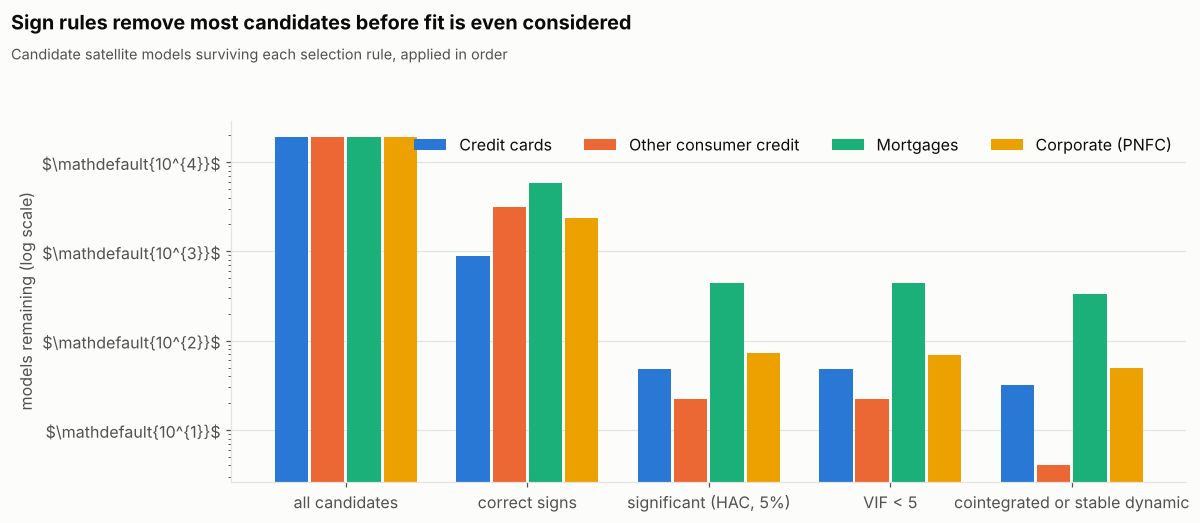

In [4]:
fig, ax = plt.subplots(figsize=(11, 4.8))
steps = fun.index.tolist()
width = 0.2
for i, p in enumerate(PORTFOLIOS):
    ax.bar(np.arange(len(steps)) + (i - 1.5) * width, fun[LABEL[p]], width=width * 0.92,
           color=PORTFOLIO_COLOURS[p], label=LABEL[p])
ax.set_yscale("log")
ax.set_xticks(range(len(steps)), steps)
ax.set_ylabel("models remaining (log scale)")
ax.legend(ncol=4, loc="upper right")
fig_title(fig, "Sign rules remove most candidates before fit is even considered",
          "Candidate satellite models surviving each selection rule, applied in order")
save(fig, "03_selection_funnel")
fig

In [5]:
static = {p: r[(~r.dynamic) & r.passes] for p, r in results.items()}
print("Static (levels-only) models passing every rule:", {LABEL[p]: len(s) for p, s in static.items()})
coint_fail = {LABEL[p]: f"{(r[(~r.dynamic) & r.sign_ok & (r.max_p < 0.05)].coint_p >= 0.10).mean():.0%}"
              for p, r in results.items()}
print("Share of sign-correct, significant static models that FAIL the cointegration test:", coint_fail)

Static (levels-only) models passing every rule: {'Credit cards': 0, 'Other consumer credit': 0, 'Mortgages': 2, 'Corporate (PNFC)': 0}
Share of sign-correct, significant static models that FAIL the cointegration test: {'Credit cards': '100%', 'Other consumer credit': '100%', 'Mortgages': '98%', 'Corporate (PNFC)': '100%'}


**Every** sign-correct, significant static model fails the cointegration test for cards, other consumer credit and corporate lending (98% for mortgages). Their residuals are non-stationary, so the apparent relationships are spurious regressions, as the EDA warned. Dynamic models, which carry the loss rate's own persistence through ρ, dominate the survivors.

## 3. The leaderboard

In [6]:
cols = ["describe", "max_p", "max_vif", "bic", "r2_adj"]
for p, r in results.items():
    print(f"\n{LABEL[p]}")
    print(r[r.passes][cols].head(5).to_string(index=False))


Credit cards
                                           describe  max_p  max_vif     bic  r2_adj
unemployment_chg_yoy[t-2] + bank_rate[t-8] + y[t-4]  0.004    1.700 -85.306   0.914
unemployment_chg_yoy[t-3] + bank_rate[t-8] + y[t-4]  0.004    1.794 -82.136   0.912
unemployment_chg_yoy[t-2] + bank_rate[t-6] + y[t-4]  0.010    1.883 -78.299   0.909
unemployment_chg_yoy[t-3] + bank_rate[t-6] + y[t-4]  0.005    1.901 -77.611   0.909
unemployment_chg_yoy[t-1] + bank_rate[t-8] + y[t-4]  0.002    1.607 -73.659   0.906

Other consumer credit
                          describe  max_p  max_vif    bic  r2_adj
unemployment_chg_yoy[t-2] + y[t-4]  0.032    1.118 19.689   0.720
unemployment_chg_yoy[t-3] + y[t-4]  0.044    1.121 19.878   0.720
           bank_rate[t-8] + y[t-4]  0.031    1.101 20.568   0.718
unemployment_chg_yoy[t-1] + y[t-4]  0.036    1.092 21.838   0.716

Mortgages
                                                                 describe  max_p  max_vif     bic  r2_adj
unemployment

## 4. Champions and challengers
**Champion:** lowest BIC among models that pass every rule. **Challenger:** the best passing model whose driver *set* differs from the champion's, to test in validation whether the conclusion depends on the choice of drivers.

In [7]:
champions, challengers = {}, {}
for p, r in results.items():
    ok = r[r.passes]
    champ = ok.iloc[0].spec
    drivers = {d for d, _ in champ.terms}
    alt = ok[ok.spec.apply(lambda s: {d for d, _ in s.terms} != drivers)]
    champions[p], _ = fit(champ, target(panel, p), macro)
    if len(alt):
        challengers[p], _ = fit(alt.iloc[0].spec, target(panel, p), macro)
    champions[p].extra = {"bic_gap_to_next": float(ok.bic.iloc[1] - ok.bic.iloc[0]) if len(ok) > 1 else None,
                          "n_passing": int(len(ok))}

save_models(champions, MODELS_DIR / "champions.json")
save_models(challengers, MODELS_DIR / "challengers.json")
pd.DataFrame({LABEL[p]: {"champion": champions[p].spec.describe(),
                         "challenger": challengers[p].spec.describe() if p in challengers else "none passes",
                         "models passing": champions[p].extra["n_passing"],
                         "BIC gap to 2nd best": champions[p].extra["bic_gap_to_next"]} for p in PORTFOLIOS}).T

,champion,challenger,models passing,BIC gap to 2nd best
Credit cards,unemployment_chg_yoy[t-2] + bank_rate[t-8] + y[t-4],unemployment_chg_yoy[t-2] + y[t-4],32,3.169
Other consumer credit,unemployment_chg_yoy[t-2] + y[t-4],bank_rate[t-8] + y[t-4],4,0.19
Mortgages,unemployment[t-2] + house_price_growth_yoy[t-1] + bank_rate[t-8] + y[t-4],unemployment[t-2] + gdp_growth_yoy[t-0] + bank_rate[t-6] + y[t-4],334,0.324
Corporate (PNFC),unemployment[t-0] + gdp_growth_yoy[t-6] + y[t-4],unemployment[t-1] + y[t-4],49,1.429


## 5. Reading the champion models
Coefficients are on the logit scale, which is hard to read directly. Two translations help:
- **Marginal effect at the jump-off point:** $\partial LR / \partial x = b \cdot LR(1 - LR)$, in percentage points of loss rate per unit of the driver, evaluated at the 2024 Q4 loss rate
- **Long-run multiplier** (dynamic models): a permanent one-unit change in a driver moves the logit by $b/(1-\rho)$ once the persistence has played out

In [8]:
def coef_table(p: str) -> pd.DataFrame:
    fm = champions[p]
    se = np.sqrt(np.diag(fm.cov))
    t = pd.DataFrame({"coef": fm.params, "HAC s.e.": se, "t": fm.params / se}, index=fm.params.index)
    lr0 = trailing_loss_rate(panel, p).loc[JUMP_OFF] / 100
    rho = fm.params.get("y_L4", 0.0)
    mask = ~t.index.isin(["const", "covid", "y_L4"])
    t.loc[mask, "marginal effect at jump-off (pp)"] = t.loc[mask, "coef"] * lr0 * (1 - lr0) * 100
    t.loc[mask, "long-run marginal effect (pp)"] = t.loc[mask, "marginal effect at jump-off (pp)"] / (1 - rho)
    return t

for p in PORTFOLIOS:
    fm = champions[p]
    print(f"\n{LABEL[p]}: {fm.spec.describe()}   (n = {fm.nobs}, adj R² = {fm.rsquared_adj:.3f}, sample {fm.sample[0]}–{fm.sample[1]})")
    print(coef_table(p).round(4).to_string())


Credit cards: unemployment_chg_yoy[t-2] + bank_rate[t-8] + y[t-4]   (n = 125, adj R² = 0.914, sample 1995Q2–2026Q2)
                          coef  HAC s.e.       t  marginal effect at jump-off (pp)  long-run marginal effect (pp)
const                   -0.487     0.183  -2.665                               NaN                            NaN
unemployment_chg_yoy_L2  0.148     0.039   3.774                             0.332                          2.641
bank_rate_L8             0.030     0.010   2.880                             0.066                          0.527
covid                   -0.057     0.061  -0.940                               NaN                            NaN
y_L4                     0.874     0.053  16.425                               NaN                            NaN

Other consumer credit: unemployment_chg_yoy[t-2] + y[t-4]   (n = 125, adj R² = 0.720, sample 1995Q2–2026Q2)
                          coef  HAC s.e.      t  marginal effect at jump-off (pp)  long-ru

**Interpretation**
- **Credit cards:** losses respond to the *change* in unemployment with a two-quarter lag, and to Bank Rate with a two-year lag, consistent with the EDA. The Bank Rate effect is the transmission of higher borrowing costs into arrears, then charge-off; it is positive here only once the loss rate's own persistence is modelled (compare the wrong-signed static coefficient in notebook 02).
- **Other consumer credit:** only four models pass every rule, all with a single macro driver. The champion uses the unemployment change; the runner-up uses Bank Rate instead, and their BIC differs by only 0.19, so **the data cannot tell them apart**. This is model uncertainty, not a modelling error, and notebook 06 compares the two under the scenario.
- **Corporate:** the unemployment *level* and GDP growth six quarters earlier. Corporate insolvencies follow the depth of a recession rather than its onset.
- **Mortgages:** unemployment, house prices and Bank Rate all enter, matching the standard affordability (unemployment, rates) and equity (house prices) channels, but on a tiny loss rate.
- **Persistence ρ** is 0.5–0.9: a shock to losses fades over two to five years, which is why stress paths peak well after the macro trough.
- **How decisive is each choice?** The card champion beats the next model by 3.2 BIC points (positive evidence by the usual rule of thumb). For other consumer credit (0.19) and mortgages (0.32) the top models are statistically tied, so their projections carry extra model uncertainty.

## 6. In-sample fit

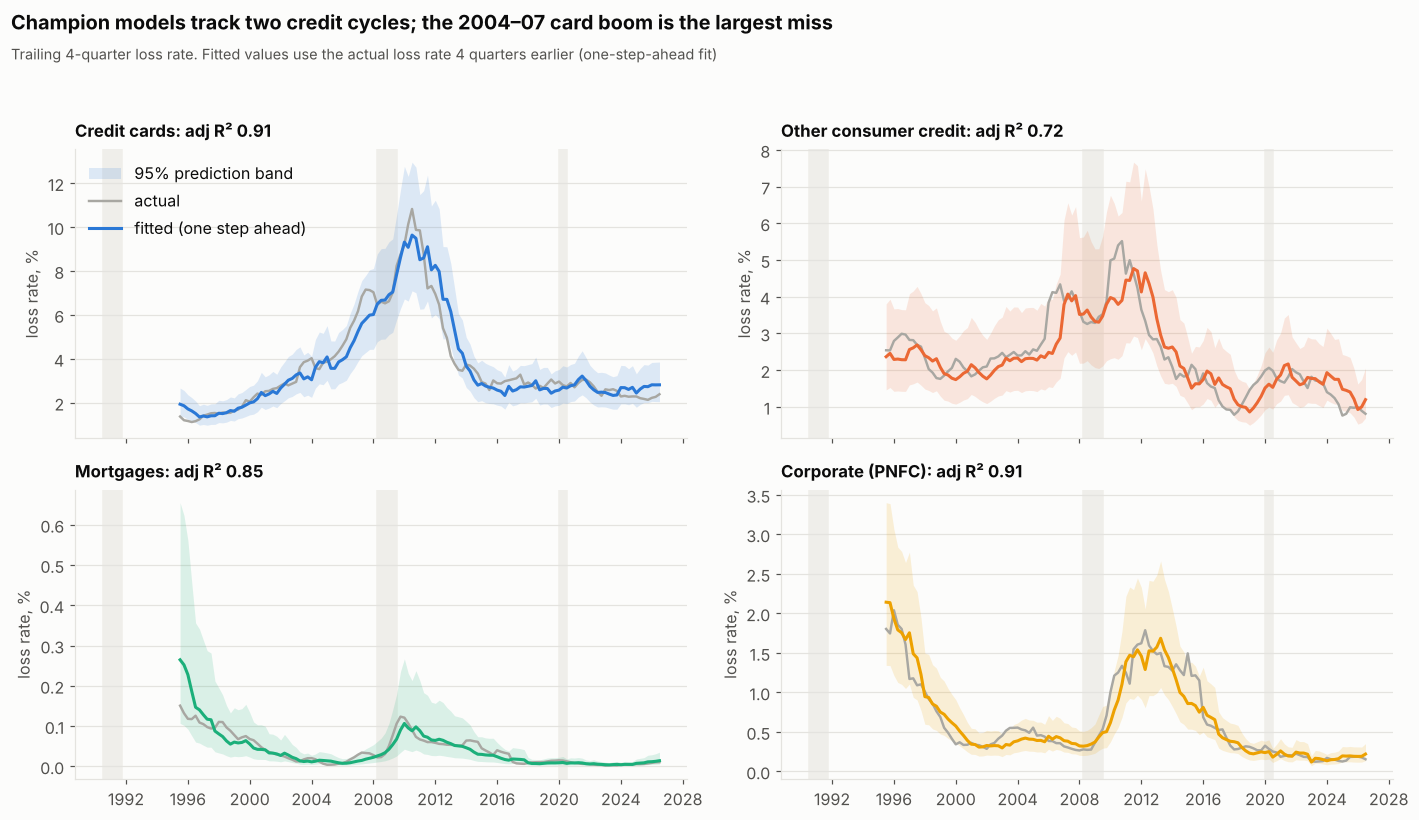

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(13, 7.5), sharex=True)
for ax, p in zip(axes.flat, PORTFOLIOS):
    fm = champions[p]
    y = target(panel, p)
    X = design(fm.spec, y, macro).loc[fm.resid.index]
    fitted = fm.predict(X)
    # 95% prediction band on the logit scale: parameter uncertainty + residual variance
    var = np.einsum("ij,jk,ik->i", X.values, fm.cov.values, X.values) + fm.resid.var()
    t = fitted.index.to_timestamp(how="end")
    shade_recessions(ax)
    ax.fill_between(t, inv_logit_pct(fitted - 1.96 * np.sqrt(var)), inv_logit_pct(fitted + 1.96 * np.sqrt(var)),
                    color=PORTFOLIO_COLOURS[p], alpha=0.15, lw=0, label="95% prediction band")
    ax.plot(t, trailing_loss_rate(panel, p).loc[fitted.index], color=GREY, lw=1.6, label="actual")
    ax.plot(t, inv_logit_pct(fitted), color=PORTFOLIO_COLOURS[p], lw=2, label="fitted (one step ahead)")
    ax.set_title(f"{LABEL[p]}: adj R² {fm.rsquared_adj:.2f}", fontsize=11, pad=8)
    ax.set_ylabel("loss rate, %")
axes[0, 0].legend(loc="upper left")
fig_title(fig, "Champion models track two credit cycles; the 2004–07 card boom is the largest miss",
          "Trailing 4-quarter loss rate. Fitted values use the actual loss rate 4 quarters earlier (one-step-ahead fit)")
save(fig, "03_champion_fit")
fig

One-step-ahead fit flatters dynamic models: each fitted value is anchored on the actual loss rate a year earlier. The real test is a multi-year projection where the model must use its *own* earlier predictions. That is done out of sample in notebook 06.

## 7. Multicollinearity in the champions

In [10]:
pd.DataFrame({LABEL[p]: vif(design(champions[p].spec, target(panel, p), macro).loc[champions[p].resid.index])
              for p in PORTFOLIOS}).round(2)

,Credit cards,Other consumer credit,Mortgages,Corporate (PNFC)
bank_rate_L8,1.45,NaN,1.32,NaN
covid,1.34,1.11,1.09,1.14
gdp_growth_yoy_L6,NaN,NaN,NaN,1.11
house_price_growth_yoy_L1,NaN,NaN,1.40,NaN
unemployment_L0,NaN,NaN,NaN,2.00
unemployment_L2,NaN,NaN,3.90,NaN
unemployment_chg_yoy_L2,1.66,1.12,NaN,NaN
y_L4,1.70,1.05,3.77,1.99


## Summary

| Portfolio | Champion drivers | Notes |
|---|---|---|
| Credit cards | Δ unemployment (t−2), Bank Rate (t−8), persistence | Bank Rate's sign is economic only in the dynamic form |
| Other consumer | Δ unemployment (t−2), persistence | Single-driver model: challenger matters |
| Corporate | Unemployment (t), GDP growth (t−6), persistence | Follows recession depth |
| Mortgages | Unemployment (t−2), house prices (t−1), Bank Rate (t−8), persistence | Lowest-confidence portfolio: tiny loss rates |

Champions are saved to `models/champions.json` (coefficients, Newey–West covariance, residuals) and are the single source used by notebooks 04–07 and the dashboard.